# Exercício

1. Gere uma amostra de tamanho $M$ de uma exponencial através do método de inversão visto em sala. Compare com uma exponencial gerada pelo numpy via histogramas. Comparem também com a densidade real da exponencial $f(x) = \lambda e^{-\lambda x}$ (isto é, seu histograma normalizado tem que ficar igual essa curva).

2. Agora considere $T_n = X_n / n$ onde $X_n$ é uma Geométrica com parâmetro $\lambda/n$. Mostre que quando $n$ é grande, isso se aproxima de uma exponencial.

3. Considere agora $X_1, X_2, \ldots$ variáveis aleatórias i.i.d. com distribuição Exponencial de parâmetro $\lambda$. Vá somando essas variáveis até que a soma ultrapasse $1$ e conte quantas delas foram somadas antes de ultrapassar $1$. Repita esse procedimento $M$ vezes e mostre empiricamente que essa quantidade segue aproximadamente uma Poisson de parâmetro $\lambda$. Compare o histograma obtido com uma Poisson gerada pelo numpy e com a função de probabilidade real da Poisson.

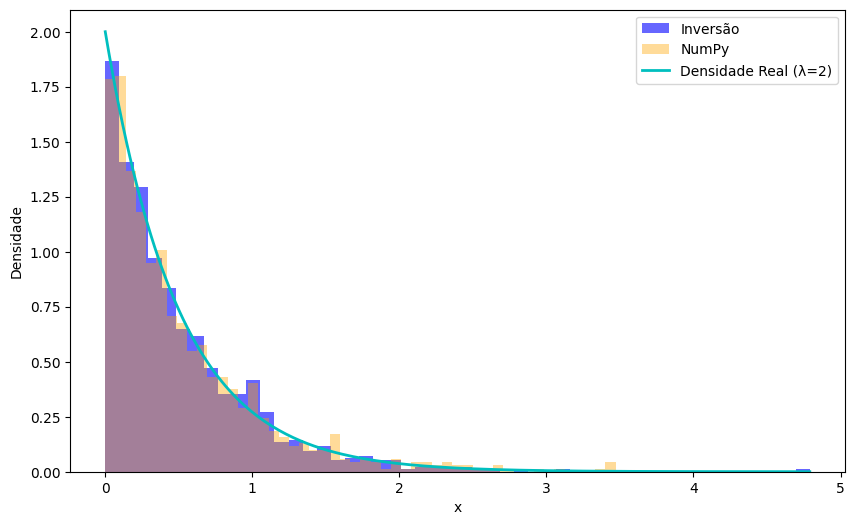

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros
M = 1000
lmb = 2

def amostraExponencialInversao(lmb, n):
  u = np.random.uniform(0, 1, n)
  return (-(1/lmb) * np.log(u))

# Densidade da exp
def f(lmb, x):
  return lmb * np.exp(-lmb * x)

amostra_exp = amostraExponencialInversao(lmb, M)
amostra_exp_np = np.random.exponential((1/lmb), size=M)

plt.figure(figsize=(10, 6))

plt.hist(amostra_exp, bins=50, density=True, alpha=0.6, label='Inversão', color='blue')
plt.hist(amostra_exp_np, bins=50, density=True, alpha=0.4, label='NumPy', color='orange')

x = np.linspace(0, np.max(amostra_exp), 200)
fx = f(lmb, x)
plt.plot(x, fx, 'c-', lw=2, label='Densidade Real (λ={})'.format(lmb))

plt.xlabel('x')
plt.ylabel('Densidade')
plt.legend()
plt.show()

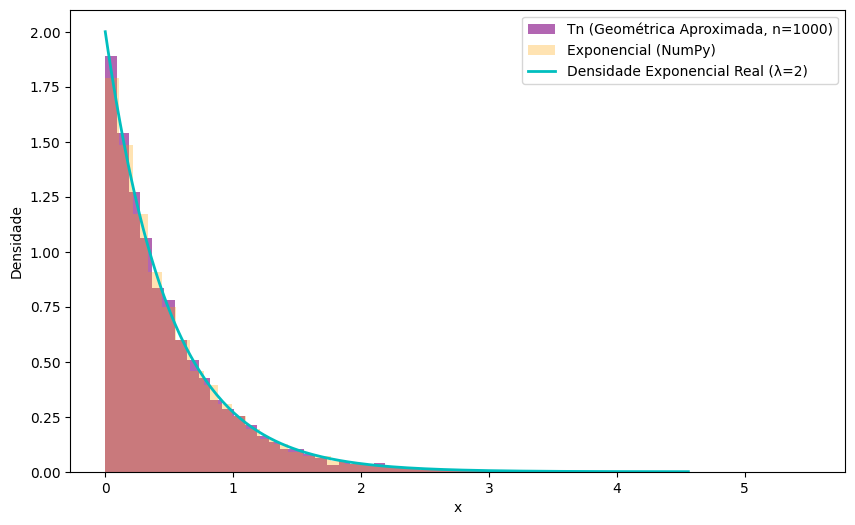

In [ ]:
M = 10000
lmb = 2
n = 1000

def amostraRecursivaGeometrica(M, p):
  u = np.random.uniform(0,1, size = M)
  return (np.floor(np.log(1 - u)/np.log(1 - p)) + 1)

def amostraGeometricaExponencial(lmb, n, M):
  p = lmb / n
  x_n = np.array(amostraRecursivaGeometrica(M, p))

  return (x_n / n)

# Densidade teórica da exponencial como referência
def f_exp(lmb, x):
  return lmb * np.exp(-lmb * x)

amostra_tn = amostraGeometricaExponencial(lmb, n, M)
amostra_tn_np = np.random.exponential((1/lmb), size=M)

plt.figure(figsize=(10, 6))

plt.hist(amostra_tn, bins=50, density=True, alpha=0.6, label='Tn (Geométrica Aproximada, n={})'.format(n), color='purple')
plt.hist(amostra_tn_np, bins=50, density=True, alpha=0.3, label='Exponencial (NumPy)', color='orange')

x = np.linspace(0, np.max(amostra_tn), 200)
fx = f_exp(lmb, x)
plt.plot(x, fx, 'c-', lw=2, label='Densidade Exponencial Real (λ={})'.format(lmb))

plt.xlabel('x')
plt.ylabel('Densidade')
plt.legend()
plt.show()

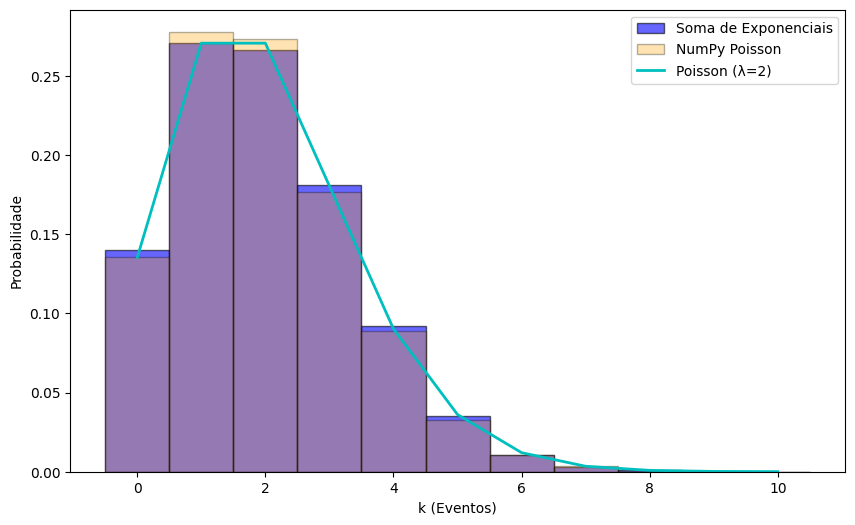

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

M = 10000
lmb = 2

def amostraPoissonExponencial(lmb, M):
  contagens = []
  for _ in range(M):
      s = 0
      k = 0
      while True:
          e = amostraExponencialInversao(lmb, 1)[0] # um ponto da exp. gambiarra, eu sei
          if s + e > 1:
              break
          s += e
          k += 1
      contagens.append(k)
  return np.array(contagens)

def f(lmb, k):
  return ((np.exp(-lmb) * (lmb ** k)) / math.factorial(k))

amostra_poisson_exp = amostraPoissonExponencial(lmb, M)
amostra_poisson_np = np.random.poisson(lam=lmb, size=M)

plt.figure(figsize=(10, 6))

v_max = max(max(amostra_poisson_exp), max(amostra_poisson_np)) # máximo entre as duas amosttras
bins = np.arange(-0.5, v_max + 1.5, 1) # tirado da documentação, solução pra não intercalar as barras. melhor visibilidade

plt.hist(amostra_poisson_exp, bins=bins,  density=True, alpha=0.6, label='Soma de Exponenciais', color='blue', edgecolor='black')
plt.hist(amostra_poisson_np, bins=bins, density=True, alpha=0.3, label='NumPy Poisson', color='orange', edgecolor='black')

k_valores = np.arange(0, v_max + 1)
f_k = [f(lmb, k) for k in k_valores]
plt.plot(k_valores, f_k, 'c-', lw=2, label='Poisson (λ={})'.format(lmb))

plt.xlabel('k (Eventos)')
plt.ylabel('Probabilidade')
plt.legend()
plt.show()